# Exercice 10 — Analyse de données capteurs

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Dimensions : (500, 5)

Informations :
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date_heure   500 non-null    datetime64[us]
 1   capteur      500 non-null    str           
 2   temperature  500 non-null    float64       
 3   humidite     480 non-null    float64       
 4   pression     500 non-null    float64       
dtypes: datetime64[us](1), float64(3), str(1)
memory usage: 22.6 KB
None

Aperçu des données :
           date_heure capteur  temperature   humidite     pression
0 2026-10-02 20:00:00  CAP_02    26.807642  57.733383  1013.141946
1 2026-10-17 06:00:00  CAP_03    25.256038  75.743383  1009.806942
2 2026-10-14 17:00:00  CAP_02    22.438524  60.465895  1008.011896
3 2026-10-10 05:00:00  CAP_01    22.006723  66.695353  1017.768839
4 2026-10-10 02:00:00  CAP_01    23.154227  56.594618  1015.382064

Valeurs manquantes :
date_he

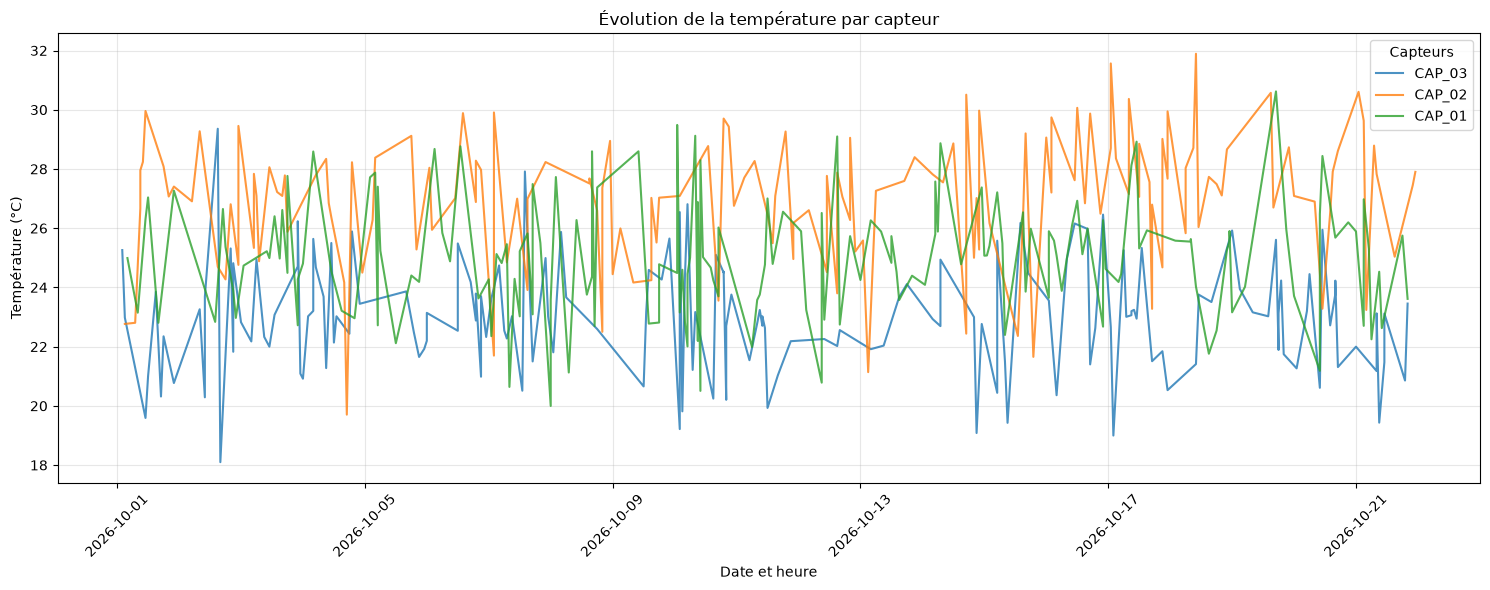

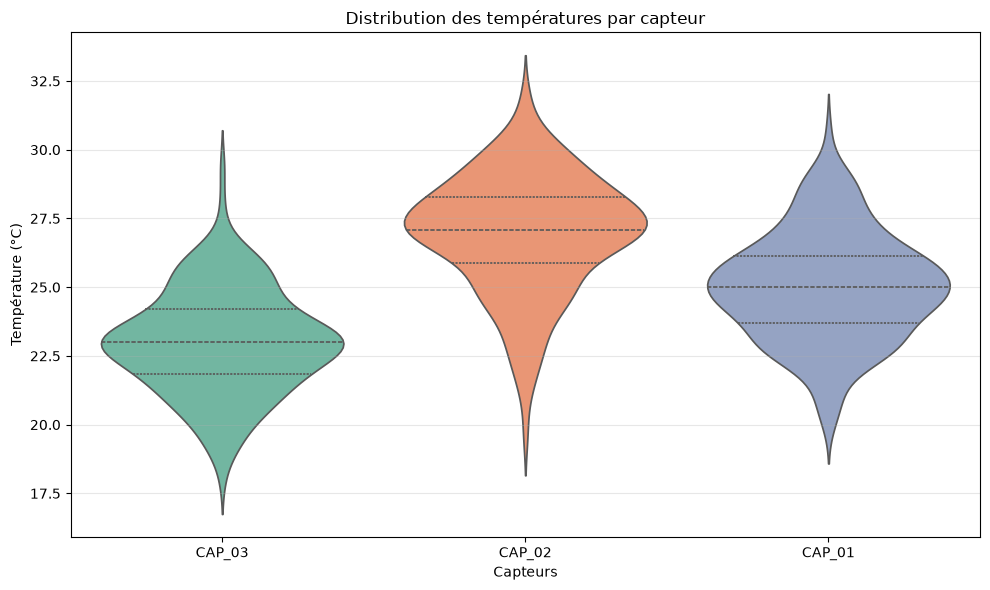


Moyennes journalières :
capteur        CAP_01     CAP_02     CAP_03
jour                                       
2026-10-01  25.259145  26.772770  22.014882
2026-10-02  24.341035  26.395522  23.356852
2026-10-03  25.218430  26.796530  23.523606
2026-10-04  24.822265  25.742728  23.379814
2026-10-05  25.206746  27.264426  22.478823


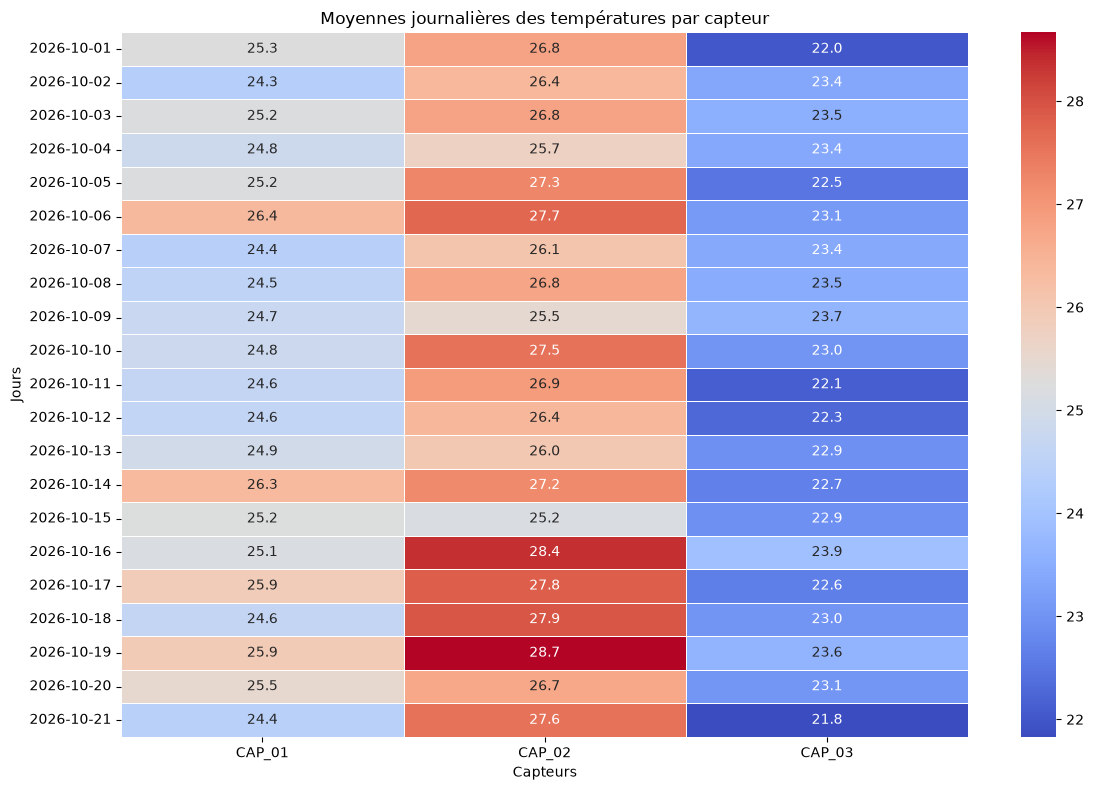

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SIMULATION DES DONNEES
# ============================================================

# Reproductibilité
rng = np.random.default_rng(42)

# 500 relevés horaires répartis sur 3 semaines et 3 capteurs
n = 500
start = pd.Timestamp("2026-10-01 00:00:00")

hours = rng.integers(0, 21 * 24, size=n)

df_capteurs = pd.DataFrame({
    "date_heure": start + pd.to_timedelta(hours, unit="h"),
    "capteur": rng.choice(
        ["CAP_01", "CAP_02", "CAP_03"],
        size=n,
        p=[0.34, 0.33, 0.33]
    )
})

# Paramètres propres à chaque capteur
sensor_params = {
    "CAP_01": {"temp": 25.0, "hum": 62.0, "press": 1012.0},
    "CAP_02": {"temp": 27.0, "hum": 58.0, "press": 1010.0},
    "CAP_03": {"temp": 23.0, "hum": 68.0, "press": 1014.0},
}

# Génération des mesures
df_capteurs["temperature"] = [
    rng.normal(sensor_params[s]["temp"], 2.0)
    for s in df_capteurs["capteur"]
]

df_capteurs["humidite"] = [
    rng.normal(sensor_params[s]["hum"], 6.0)
    for s in df_capteurs["capteur"]
]

df_capteurs["pression"] = [
    rng.normal(sensor_params[s]["press"], 3.0)
    for s in df_capteurs["capteur"]
]


# ============================================================
# 2. INTRODUCTION DES VALEURS ABERRANTES
# ============================================================

# Injecter des anomalies dans la température
indices_anomalies = rng.choice(
    df_capteurs.index,
    size=10,
    replace=False
)

df_capteurs.loc[indices_anomalies, "temperature"] = rng.choice(
    [65, 75, -15, -20],
    size=10
)


# ============================================================
# 3. INTRODUCTION DES VALEURS MANQUANTES
# ============================================================

# Introduire 20 valeurs manquantes dans l'humidité
indices_manquants = rng.choice(
    df_capteurs.index,
    size=20,
    replace=False
)

df_capteurs.loc[indices_manquants, "humidite"] = np.nan


# ============================================================
# 4. PREPARATION ET INSPECTION DES DONNEES
# ============================================================

df_capteurs["date_heure"] = pd.to_datetime(
    df_capteurs["date_heure"]
)

print("Dimensions :", df_capteurs.shape)

print("\nInformations :")
print(df_capteurs.info())

print("\nAperçu des données :")
print(df_capteurs.head())

print("\nValeurs manquantes :")
print(df_capteurs.isna().sum())


# ============================================================
# 5. DETECTION DES ANOMALIES DE TEMPERATURE
# METHODE : IQR (Interquartile Range)
# ============================================================

Q1 = df_capteurs["temperature"].quantile(0.25)
Q3 = df_capteurs["temperature"].quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Identifier les anomalies
anomalies = (
    (df_capteurs["temperature"] < borne_inf) |
    (df_capteurs["temperature"] > borne_sup)
)

print("\nNombre d'anomalies détectées :", anomalies.sum())

# Neutraliser les anomalies avec la médiane du capteur
for capteur in df_capteurs["capteur"].unique():

    masque = (
        (df_capteurs["capteur"] == capteur) &
        anomalies
    )

    mediane = df_capteurs.loc[
        df_capteurs["capteur"] == capteur,
        "temperature"
    ].median()

    df_capteurs.loc[masque, "temperature"] = mediane


# ============================================================
# 6. IMPUTATION DES VALEURS MANQUANTES D'HUMIDITE
# ============================================================

# Remplacer les valeurs manquantes par la médiane du capteur
df_capteurs["humidite"] = (
    df_capteurs.groupby("capteur")["humidite"]
    .transform(lambda groupe: groupe.fillna(groupe.median()))
)


# Vérification après nettoyage
print("\nValeurs manquantes après traitement :")
print(df_capteurs.isna().sum())

print("\nRésumé statistique :")
print(df_capteurs.describe())


# ============================================================
# 7. TRIER LES DONNEES PAR DATE
# ============================================================

df_capteurs = df_capteurs.sort_values("date_heure")


# ============================================================
# 8. EVOLUTION DES TEMPERATURES PAR CAPTEUR
# ============================================================

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=df_capteurs,
    x="date_heure",
    y="temperature",
    hue="capteur",
    estimator=None,
    alpha=0.8
)

plt.title("Évolution de la température par capteur")
plt.xlabel("Date et heure")
plt.ylabel("Température (°C)")
plt.legend(title="Capteurs")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 9. DISTRIBUTION DES TEMPERATURES PAR CAPTEUR
# ============================================================

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_capteurs,
    x="capteur",
    y="temperature",
    hue="capteur",
    palette="Set2",
    inner="quart",
    legend=False
)

plt.title("Distribution des températures par capteur")
plt.xlabel("Capteurs")
plt.ylabel("Température (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 10. CALCUL DES MOYENNES JOURNALIERES
# ============================================================

df_capteurs["jour"] = df_capteurs["date_heure"].dt.date

moyennes = df_capteurs.pivot_table(
    index="jour",
    columns="capteur",
    values="temperature",
    aggfunc="mean"
)

print("\nMoyennes journalières :")
print(moyennes.head())


# ============================================================
# 11. HEATMAP DES TEMPERATURES
# ============================================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    moyennes,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Moyennes journalières des températures par capteur")
plt.xlabel("Capteurs")
plt.ylabel("Jours")

plt.tight_layout()
plt.show()
